# 06 – Trực quan hoá filter lớp conv cuối

In [1]:
# Colab: Runtime > Change runtime type > GPU (T4)
from google.colab import drive
drive.mount('/content/drive')
import sys
PROJECT = "/content/drive/MyDrive/FER2013_PyTorch"
sys.path.insert(0, PROJECT)
from common import *
print("Device:", DEV, "| torch", torch.__version__)

Mounted at /content/drive
Device: cpu | torch 2.14.1+cpu


In [2]:
from data import *
from models import *
import pandas as pd
rows = [json.loads(p.read_text()) for p in RUNS_DIR.glob('*/results.json')]
BEST = max(rows, key=lambda r: r['val_acc'])['exp_name']   # hoặc gán tay, ví dụ BEST = 'base'
print('Mô hình trực quan hoá:', BEST)

ck = torch.load(RUNS_DIR/BEST/'best.pt', map_location=DEV); cfg = ck['cfg']; mean, std = ck['mean'], ck['std']
model = build_model(cfg['model'], cfg['img_size'], cfg['bn'], cfg['conv_drop'], cfg['fc_drop'], False).to(DEV)
model.load_state_dict(ck['state_dict']); model.eval()
convs = [m for m in model.modules() if isinstance(m, nn.Conv2d)]; last = last_conv(model)
VIZ = RUNS_DIR/BEST/'viz'; VIZ.mkdir(exist_ok=True)

Mô hình trực quan hoá: A_vgg16_ft


## 6.1 Trọng số conv đầu và conv cuối
Filter 3×3 của conv cuối được lấy trung bình theo kênh vào và hiển thị top-64 theo chuẩn L2; hình này khó diễn giải trực tiếp nên xem thêm 6.2.

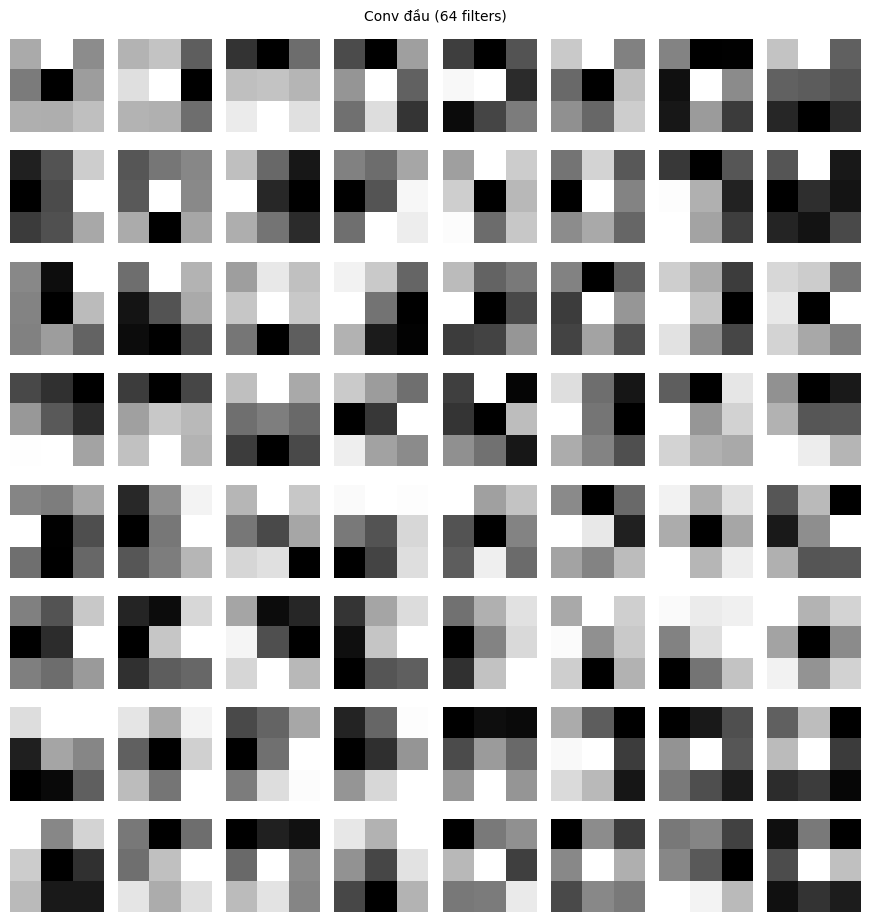

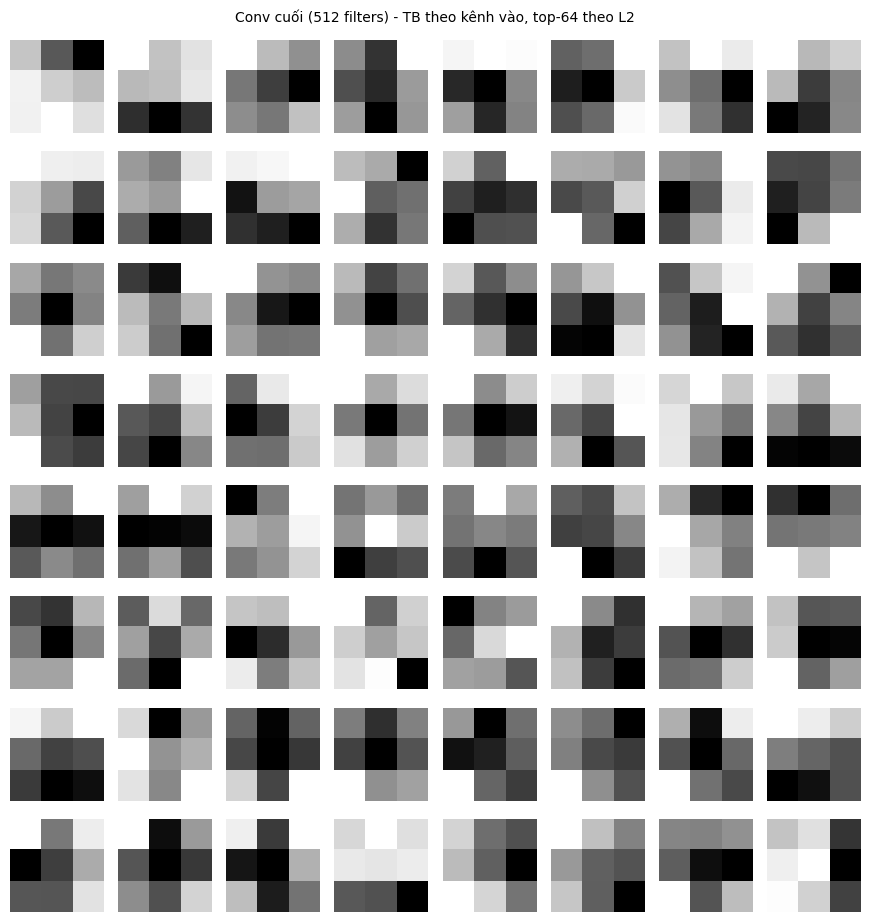

In [3]:
def show_weights(conv, title, k=64):
    w = conv.weight.detach().cpu().numpy()
    idx = np.argsort(-np.linalg.norm(w.reshape(w.shape[0], -1), axis=1))[:k]
    imgs = [w[i].mean(0) for i in idx]; n = int(np.ceil(np.sqrt(len(imgs))))
    fig, axs = plt.subplots(n, n, figsize=(n*1.1, n*1.1+.6))
    for a in axs.ravel(): a.axis('off')
    for a, im in zip(axs.ravel(), imgs): a.imshow(im, cmap='gray')
    fig.suptitle(title, fontsize=10); fig.tight_layout(); return fig

f = show_weights(convs[0], f'Conv đầu ({convs[0].out_channels} filters)'); f.savefig(VIZ/'filters_first_conv.png', dpi=140); plt.show()
f = show_weights(last, f'Conv cuối ({last.out_channels} filters) - TB theo kênh vào, top-64 theo L2'); f.savefig(VIZ/'filters_last_conv.png', dpi=140); plt.show()

## 6.2 Ảnh kích hoạt cực đại của filter conv cuối

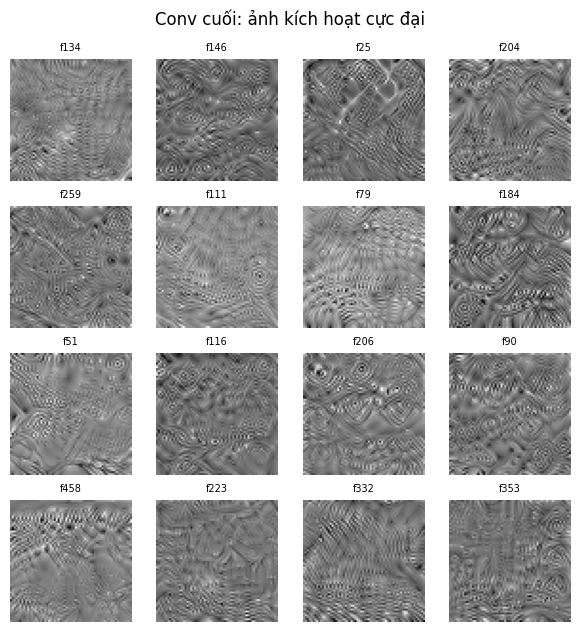

In [4]:
def max_activation(model, conv, size, n=16, steps=120):
    store = {}; h = conv.register_forward_hook(lambda m,i,o: store.__setitem__('a', o))
    chans = torch.argsort(-conv.weight.detach().flatten(1).norm(dim=1))[:n].tolist(); imgs = []
    for c in chans:
        x = (torch.randn(1,1,size,size, device=DEV)*0.1).requires_grad_(True); opt = torch.optim.Adam([x], lr=0.05)
        for _ in range(steps):
            opt.zero_grad(); model(x); (-store['a'][0,c].mean() + 1e-3*x.pow(2).sum()).backward(); opt.step()
        im = x.detach()[0,0].cpu().numpy(); imgs.append((im-im.min())/(im.max()-im.min()+1e-8))
    h.remove(); return chans, imgs

chans, imgs = max_activation(model, last, cfg['img_size'])
fig, axs = plt.subplots(4, 4, figsize=(6,6.4))
for a, im, c in zip(axs.ravel(), imgs, chans): a.imshow(im, cmap='gray'); a.set_title(f'f{c}', fontsize=7); a.axis('off')
fig.suptitle('Conv cuối: ảnh kích hoạt cực đại'); fig.tight_layout(); fig.savefig(VIZ/'filters_last_conv_maxact.png', dpi=140); plt.show()

## 6.3 Feature map conv cuối cho 7 lớp cảm xúc

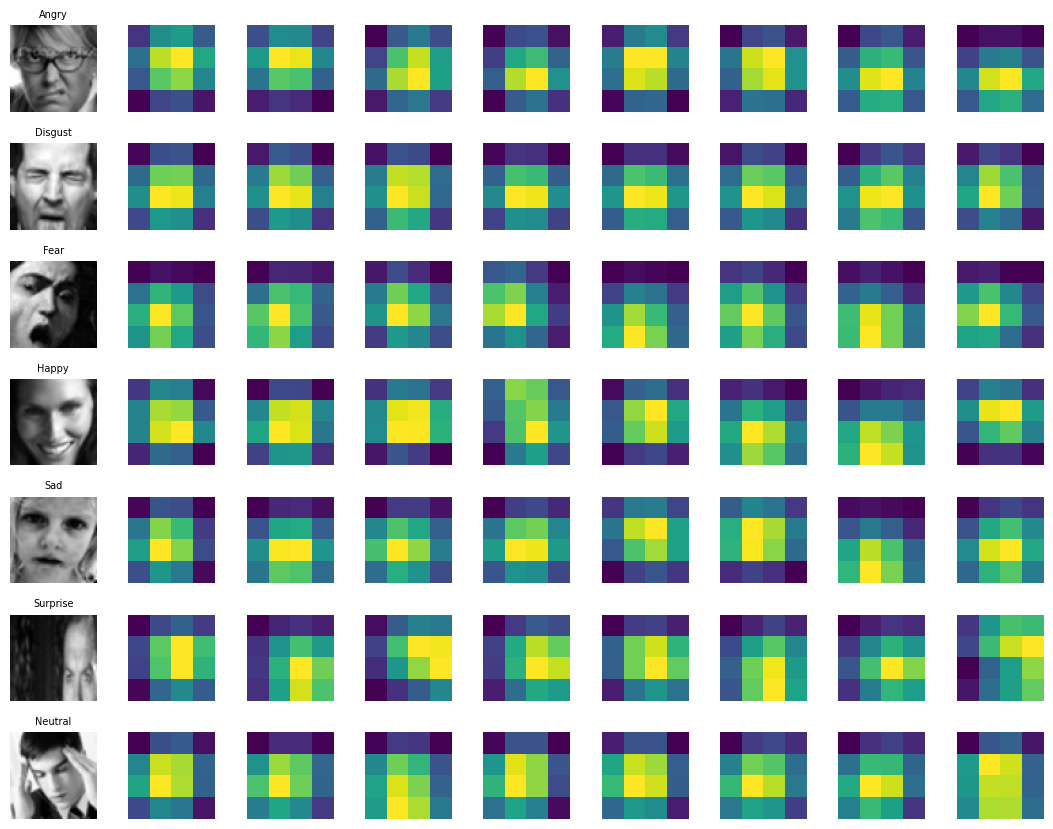

In [5]:
tf = build_transforms(False, 'none', cfg['img_size'], mean, std)
xt, yt = get_data()['test']; sel = [int(np.where(yt==c)[0][0]) for c in range(7)]
xs = [tf(Image.fromarray(xt[i])).unsqueeze(0).to(DEV) for i in sel]

store = {}; h = last.register_forward_hook(lambda m,i,o: store.__setitem__('a', o.detach()))
fig, axs = plt.subplots(7, 9, figsize=(10.8, 8.4))
for r, (x, nm) in enumerate(zip(xs, CLASSES)):
    with torch.no_grad(): model(x)
    a = store['a'][0].cpu(); top = torch.argsort(-a.flatten(1).mean(1))[:8].tolist()
    axs[r,0].imshow(x[0,0].cpu(), cmap='gray'); axs[r,0].set_title(nm, fontsize=7)
    for j, c in enumerate(top): axs[r,j+1].imshow(a[c], cmap='viridis')
    for a_ in axs[r]: a_.axis('off')
h.remove(); fig.tight_layout(); fig.savefig(VIZ/'featuremaps_last_conv.png', dpi=130); plt.show()

## 6.4 Grad-CAM

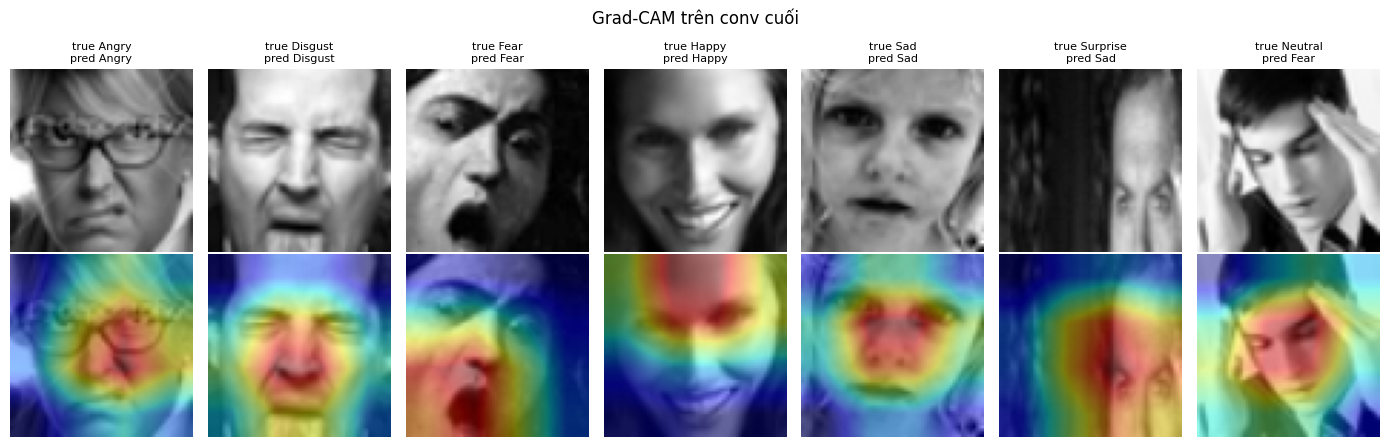

In [6]:
def gradcam(model, conv, x):
    st = {}
    def fwd(m, i, o):
        st['a'] = o; o.register_hook(lambda g: st.__setitem__('g', g))
    h = conv.register_forward_hook(fwd); model.zero_grad(); out = model(x); cls = int(out.argmax(1))
    out[0, cls].backward(); h.remove()
    cam = F.relu((st['g'].mean((2,3), keepdim=True) * st['a']).sum(1, keepdim=True))
    cam = F.interpolate(cam, size=x.shape[-2:], mode='bilinear', align_corners=False)[0,0]
    return ((cam-cam.min())/(cam.max()-cam.min()+1e-8)).detach().cpu().numpy(), cls

fig, axs = plt.subplots(2, 7, figsize=(14,4.6))
for j, x in enumerate(xs):
    cam, pred = gradcam(model, last, x); img = x[0,0].detach().cpu().numpy()
    axs[0,j].imshow(img, cmap='gray'); axs[0,j].set_title(f'true {CLASSES[j]}\npred {CLASSES[pred]}', fontsize=8)
    axs[1,j].imshow(img, cmap='gray'); axs[1,j].imshow(cam, cmap='jet', alpha=0.45)
    for a_ in axs[:,j]: a_.axis('off')
fig.suptitle('Grad-CAM trên conv cuối'); fig.tight_layout(); fig.savefig(VIZ/'gradcam.png', dpi=130); plt.show()